# 8 · What the graph actually buys

*Part 8. Previously: `07_design_evaluation.ipynb` (the design and the cell table).*

This notebook answers five questions, one figure each, in plain language:

1. **When** does the graph help? (a dose-response curve over the cue strength)
2. **What are the two levers** - better search scope or better ordering?
3. **Where** does the dictionary order fail? (the coverage cliff)
4. **Who** fails on what? (a per-question map)
5. **Does model size matter** for this effect?

The short answer up front: the graph is not "better retrieval". It is a way to
put a **buried but cued** sense back into the visible list. When the sense is
already visible, it changes nothing; when there is no cue in the sentence, it
cannot help either.

In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

import elexai.analysis as al
from elexai.retrieval.chunks import load_chunks

al.scientific_style()
pd.set_option("display.width", 220)
REPO = al.REPO_ROOT


def load_run(name):
    try:
        run_id = al.find_run(name)
    except KeyError:
        return None
    cfg = yaml.safe_load(
        (REPO / "runs" / run_id / "config.resolved.yaml").read_text(encoding="utf-8")
    )
    qpath = Path(cfg["questions_path"])
    if not qpath.is_absolute():
        qpath = REPO / qpath
    return run_id, al.load_answers(run_id, questions_path=qpath), qpath


RUNS = {
    "GaMS 9B": "gams-9b-api-v2",
    "GaMS 12B": "gams3-12b-api-v2",
    "GaMS 27B": "gams2-27b-api-v2",
    "luna": "skeleton-cap3-v2",
    "Gemini": "gemini4-argon-cap3-v2",
}
BLEMMA = {"luna": "skeleton-cap3-blemma-v2", "GaMS 12B": "gams3-12b-api-blemma-v2"}

loaded = {label: load_run(name) for label, name in RUNS.items()}
loaded = {k: v for k, v in loaded.items() if v is not None}
QPATH = next(iter(loaded.values()))[2]
questions = al.load_questions_table(QPATH).set_index("question_id")
chunks = {c.sense_id: c for c in load_chunks(al.LEXICAL_CORE)}
by_lemma = defaultdict(list)
for chunk in chunks.values():
    by_lemma[(chunk.lemma.lower(), chunk.pos)].append(chunk)


def cue_count(qid: str) -> int:
    q = questions.loc[qid]
    gold = chunks[str(q["gold_sense_id"])]
    siblings = by_lemma[(gold.lemma.lower(), gold.pos)]
    return len(al.cue_hits(q["context_sentence"], gold, siblings, target_word=q["target_word"]))


cue_map = {
    qid: cue_count(qid)
    for qid in questions.index
    if questions.loc[qid, "question_type"] == "sense_disambiguation"
}
pos_map = {
    qid: chunks[str(questions.loc[qid, "gold_sense_id"])].position
    for qid in questions.index
}

frames = []
for label, (run_id, df, _qpath) in loaded.items():
    df = df.copy()
    df["model"] = label
    df["cues"] = df["question_id"].map(cue_map)
    df["position"] = df["question_id"].map(pos_map)
    frames.append(df)
allq = pd.concat(frames, ignore_index=True)
sense = allq[allq["question_type"] == "sense_disambiguation"].copy()

print("runs:", {label: value[0] for label, value in loaded.items()})
print("sense questions:", sense["question_id"].nunique(), "| answers:", len(sense))
print("cue distribution:", sense.drop_duplicates("question_id")["cues"].value_counts().sort_index().to_dict())

runs: {'GaMS 9B': '20261120-153758_gams-9b-api-v2', 'GaMS 12B': '20261120-153413_gams3-12b-api-v2', 'GaMS 27B': '20261120-153754_gams2-27b-api-v2', 'luna': '20261120-153409_skeleton-cap3-v2', 'Gemini': '20261121-110346_gemini4-argon-cap3-v2'}
sense questions: 36 | answers: 900
cue distribution: {0.0: 17, 1.0: 8, 2.0: 8, 3.0: 2, 4.0: 1}


## 1 · When does the graph help? (dose-response)

Each question is placed in a bin by **how many distinctive cue words** its
sentence contains: words from the gold sense's own dictionary neighbourhood
(its collocations, definition, synonyms) that no other sense of the same word
shares. The curves pool the five models; the number under each bin is the number
of *questions* in it (each measured on every model).

**How to read it:** the orange line (D, graph order) rises with the cue count:
with no cue it is no better than C; with one cue it jumps to ~0.97; with two or
more it is perfect. The green line (C) *falls*, because the cued questions are
exactly the buried ones by design - the cue was attached to the hard cases. The
graph turns that around. That is the whole mechanism in one picture.

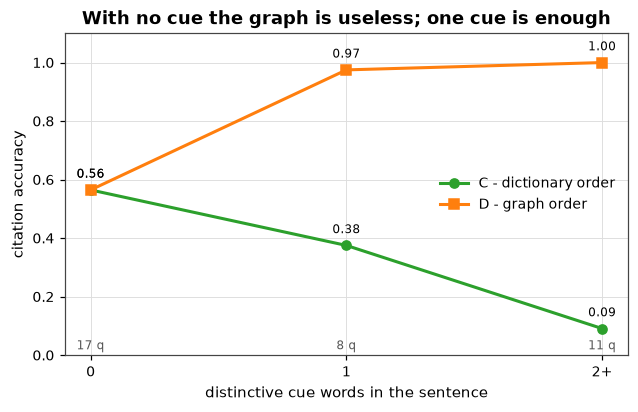

In [2]:
sense["cue_bin"] = pd.cut(sense["cues"], bins=[-1, 0, 1, 99], labels=["0", "1", "2+"])
fig, ax = plt.subplots(figsize=(6.6, 3.8))
for variant, color, marker, label in (
    ("C", "#2ca02c", "o", "C - dictionary order"),
    ("D", "#ff7f0e", "s", "D - graph order"),
):
    sub = sense[sense["variant"] == variant]
    means = sub.groupby("cue_bin", observed=True)["correct"].mean()
    ax.plot(
        [str(x) for x in means.index],
        means.values,
        marker=marker,
        color=color,
        linewidth=2,
        label=label,
    )
    for x, y in zip([str(x) for x in means.index], means.values, strict=True):
        ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
counts = sense.drop_duplicates("question_id")["cue_bin"].value_counts().sort_index()
for x, n in counts.items():
    ax.annotate(f"{n} q", (str(x), 0.02), ha="center", fontsize=8, color="#555555")
ax.set_xlabel("distinctive cue words in the sentence")
ax.set_ylabel("citation accuracy")
ax.set_ylim(0, 1.1)
ax.legend(loc="center right", fontsize=9)
ax.set_title("With no cue the graph is useless; one cue is enough")
al.save_figure(fig, "08_dose_response")
plt.show()

## 2 · The two levers: search scope vs candidate order

Variant B searches the **whole dictionary** (131k definitions) and often
retrieves a different word. `B-lemma` restricts the search to the target word's
own senses - a **scope** fix. C vs D is an **order** fix on the same candidates.
The figure puts both levers side by side, per design cell.

**How to read it:** the biggest single jump is B → B-lemma (blue to dark blue):
**scope** is the dominant lever. The C → D jump (green to orange) exists only in
S3 (buried + cued) and S4 (buried, no cue) - where the gold is outside the
visible list. Where the gold is visible (S1/S2), order changes nothing.

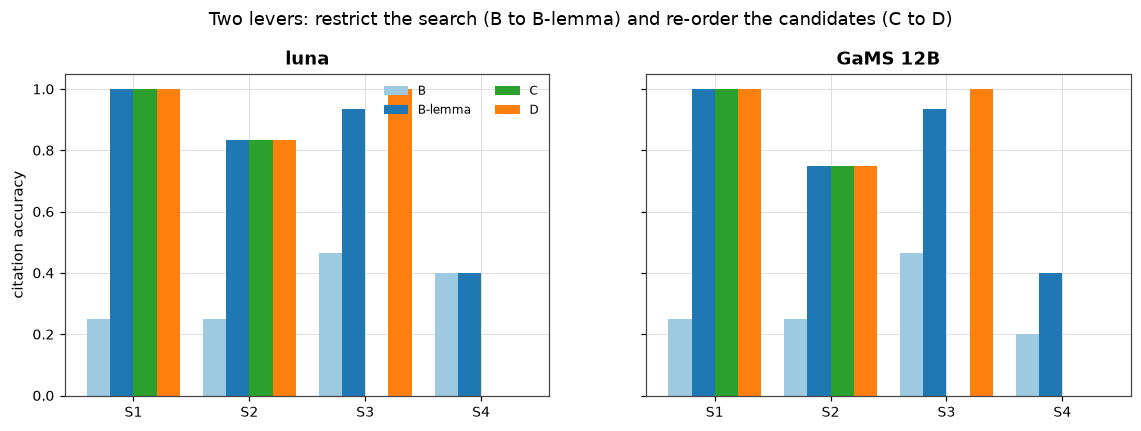

In [3]:
def method_table(full_run: str, blemma_run: str) -> pd.DataFrame:
    _rid, df, _q = load_run(full_run)
    _bid, bdf, _bq = load_run(blemma_run)
    d = df[df["question_type"] == "sense_disambiguation"]
    table = pd.DataFrame(
        {
            "B": d[d["variant"] == "B"].set_index("question_id")["correct"],
            "B-lemma": bdf[bdf["variant"] == "B"].set_index("question_id")["correct"],
            "C": d[d["variant"] == "C"].set_index("question_id")["correct"],
            "D": d[d["variant"] == "D"].set_index("question_id")["correct"],
        }
    )
    table["cell"] = d.drop_duplicates("question_id").set_index("question_id")["design_cell"]
    return table


cells_order = ["S1_shallow_cued", "S2_shallow_nocue", "S3_buried_cued", "S4_buried_nocue"]
colors = {"B": "#9ecae1", "B-lemma": "#1f77b4", "C": "#2ca02c", "D": "#ff7f0e"}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, (label, blemma_name) in zip(axes, BLEMMA.items(), strict=True):
    try:
        table = method_table(RUNS[label], blemma_name)
    except KeyError:
        ax.set_title(f"{label} (missing)")
        continue
    grouped = table.groupby("cell")[["B", "B-lemma", "C", "D"]].mean().reindex(cells_order)
    x = np.arange(len(cells_order))
    for i, method in enumerate(["B", "B-lemma", "C", "D"]):
        ax.bar(x + (i - 1.5) * 0.2, grouped[method].values, width=0.2, color=colors[method], label=method)
    ax.set_xticks(x)
    ax.set_xticklabels([c.split("_")[0] for c in cells_order])
    ax.set_title(label)
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("citation accuracy")
axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("Two levers: restrict the search (B to B-lemma) and re-order the candidates (C to D)", y=1.03)
al.save_figure(fig, "08_two_levers")
plt.show()

## 3 · Where the dictionary order fails: the coverage cliff

The x-axis is the gold sense's **position in the dictionary order** (1 = first
sense of the word). The cap is 3, so positions 1-3 are visible and 4+ are not.
The two panels separate the questions **with** a cue from those **without** -
otherwise position and cue are confounded (the design attaches cues to the
buried cases).

**How to read it:** in both panels C falls off a cliff at position 4 - it cannot
show what it does not list. D removes the cliff **only in the left panel**: with a
cue it stays at ~1.0; without one it falls with C. That is the honest version of
"the graph fixes the buried cases".

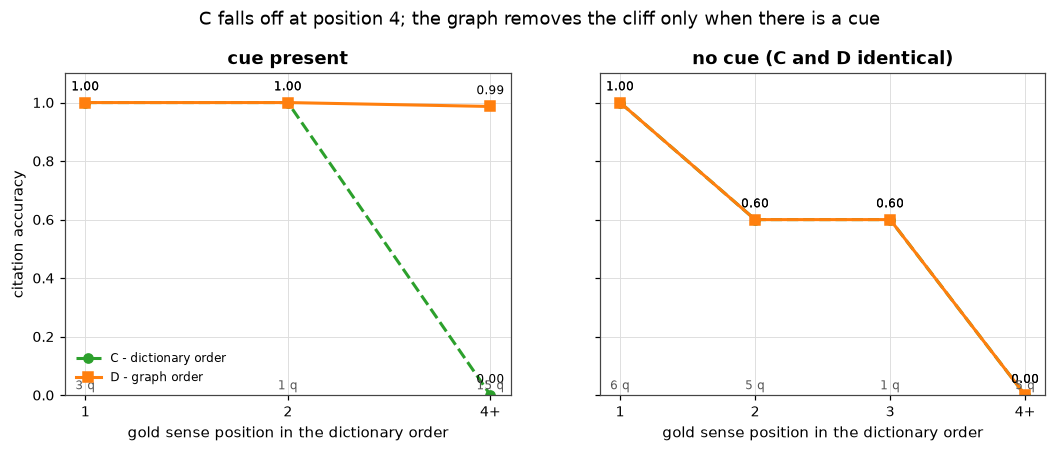

In [4]:
cd = sense[sense["variant"].isin(["C", "D"])].copy()
cd["pos_bin"] = pd.cut(cd["position"], bins=[0, 1, 2, 3, 99], labels=["1", "2", "3", "4+"])
cd["cue_group"] = np.where(cd["cues"] > 0, "cue present", "no cue")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for ax, group in zip(axes, ["cue present", "no cue"], strict=True):
    sub = cd[cd["cue_group"] == group]
    for variant, color, marker, style, label in (
        ("C", "#2ca02c", "o", "--", "C - dictionary order"),
        ("D", "#ff7f0e", "s", "-", "D - graph order"),
    ):
        part = sub[sub["variant"] == variant]
        means = part.groupby("pos_bin", observed=True)["correct"].mean()
        ax.plot(
            [str(x) for x in means.index],
            means.values,
            marker=marker,
            linestyle=style,
            color=color,
            linewidth=2,
            label=label,
        )
        for x, y in zip([str(x) for x in means.index], means.values, strict=True):
            ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    counts = sub.drop_duplicates("question_id")["pos_bin"].value_counts().sort_index()
    for x, n in counts.items():
        ax.annotate(f"{n} q", (str(x), 0.02), ha="center", fontsize=8, color="#555555")
    ax.set_xlabel("gold sense position in the dictionary order")
    ax.set_title("no cue (C and D identical)" if group == "no cue" else group)
    ax.set_ylim(0, 1.1)
axes[0].set_ylabel("citation accuracy")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("C falls off at position 4; the graph removes the cliff only when there is a cue", y=1.03)
al.save_figure(fig, "08_coverage_cliff")
plt.show()

## 4 · Who fails on what? (one row per question)

Rows are the 36 sense questions, grouped by cell; the parenthesis after the word
is the number of distinctive cues. Columns are the four ways of answering with a
candidate list: B-lemma, C, D and the oracle (gold shown). Green = correct
citation, red = wrong or missing.

**How to read it:** the S3 block is a red column under C and a green column
under D - the same questions, two orderings. The S4 block is red for everyone
(no cue, nothing to rank on). S1/S2 are almost all green: when the gold is
visible, the model usually finds it.

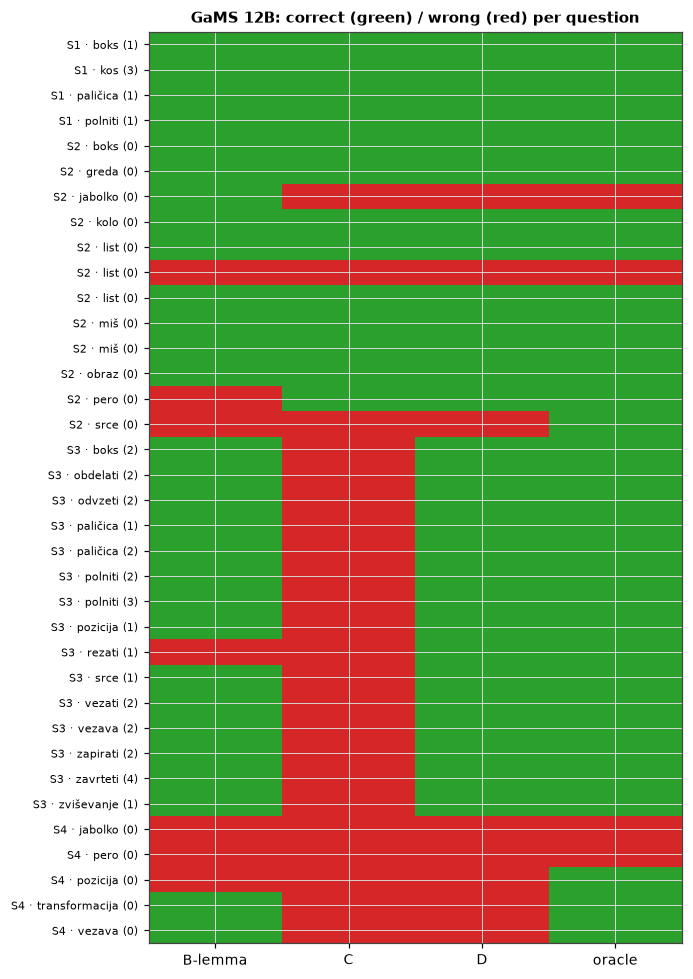

In [5]:
try:
    _rid, df12, _q = load_run(RUNS["GaMS 12B"])
    _bid, b12, _bq = load_run(BLEMMA["GaMS 12B"])
    per_q = pd.DataFrame(
        {
            "B-lemma": b12[b12["variant"] == "B"].set_index("question_id")["correct"],
            "C": df12[df12["variant"] == "C"].set_index("question_id")["correct"],
            "D": df12[df12["variant"] == "D"].set_index("question_id")["correct"],
            "oracle": df12[df12["variant"] == "oracle"].set_index("question_id")["correct"],
        }
    )
    meta = questions.loc[per_q.index]
    per_q = per_q[meta["question_type"] == "sense_disambiguation"]
    meta = meta.loc[per_q.index]
    per_q["cell"] = meta["design_cell"]
    per_q["lemma"] = meta["lemma"]
    per_q["cues"] = [cue_map.get(q, 0) for q in per_q.index]
    per_q = per_q.sort_values(["cell", "lemma"])

    labels = [
        f"{row.cell.split('_')[0]} · {row.lemma} ({row.cues})"
        for row in per_q.itertuples()
    ]
    matrix = per_q[["B-lemma", "C", "D", "oracle"]].astype(int).values
    fig, ax = plt.subplots(figsize=(6.4, 9))
    ax.imshow(matrix, aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#d62728", "#2ca02c"]), vmin=0, vmax=1)
    ax.set_xticks(range(4))
    ax.set_xticklabels(["B-lemma", "C", "D", "oracle"])
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=7)
    ax.set_title("GaMS 12B: correct (green) / wrong (red) per question", fontsize=10)
    fig.tight_layout()
    al.save_figure(fig, "08_question_map")
    plt.show()
except KeyError:
    print("GaMS 12B or its B-lemma run is missing")

## 5 · Does model size matter?

The S3 cell (buried + cued) on the five models. C is zero for all of them by
construction, so only D is shown.

**How to read it:** the bars are flat - 9B, 12B, 27B, the large API model and
Gemini all land at ~1.0. On this task the **method** (re-ranking by the
dictionary neighbourhood) matters, not the size of the model.

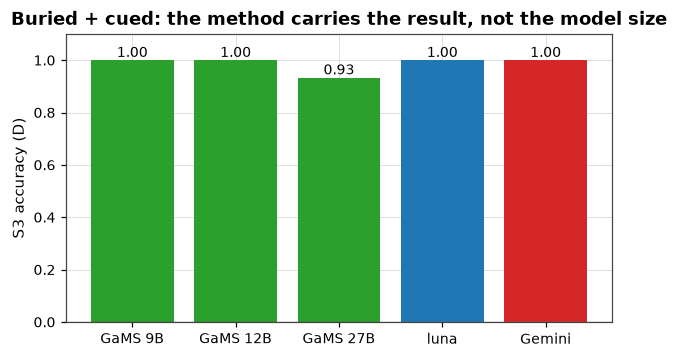

In [6]:
s3 = sense[(sense["design_cell"] == "S3_buried_cued") & (sense["variant"] == "D")]
means = s3.groupby("model")["correct"].mean().reindex(["GaMS 9B", "GaMS 12B", "GaMS 27B", "luna", "Gemini"]).dropna()
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bars = ax.bar(means.index, means.values, color=["#2ca02c", "#2ca02c", "#2ca02c", "#1f77b4", "#d62728"])
for bar, value in zip(bars, means.values, strict=True):
    ax.annotate(f"{value:.2f}", (bar.get_x() + bar.get_width() / 2, value), ha="center", va="bottom", fontsize=9)
ax.axhline(0.0, color="#555555", linewidth=0.8)
ax.set_ylim(0, 1.1)
ax.set_ylabel("S3 accuracy (D)")
ax.set_title("Buried + cued: the method carries the result, not the model size")
al.save_figure(fig, "08_model_size")
plt.show()

## 6 · The hard cases, in words

The cells above are built from dictionary collocations. The failures that remain
are of two kinds, and the **oracle column tells them apart**: if the model gets
the item right when the gold sense is shown, the failure is in the list/ranking;
if it still fails, the model does not recognise the reading at all (figurative or
multi-word use). The table shows the GaMS 12B answer for the clearest cases.

In [7]:
def describe(sid):
    if sid is None or (isinstance(sid, float) and pd.isna(sid)):
        return "-"
    chunk = chunks.get(str(sid))
    if chunk is None:
        return str(sid)
    return f"{chunk.lemma}: {chunk.definition[:40]}"


def diagnosis(qid):
    row = {}
    for variant in ("C", "D", "oracle"):
        sub = df12[(df12["question_id"] == qid) & (df12["variant"] == variant)]
        row[variant] = bool(sub.iloc[0]["correct"]) if not sub.empty else False
    if row["C"] and row["D"]:
        return "control (all correct)"
    if row["oracle"]:
        return "the gold is usable; the list/ranking failed"
    return "the model does not recognise the reading"


try:
    _rid, df12, _q = load_run(RUNS["GaMS 12B"])
    ids = ["q-025", "q-026", "q-029", "q-030", "v2-041", "v2-042", "v2-043", "v2-011"]
    rows = []
    for qid in ids:
        if qid not in questions.index:
            continue
        q = questions.loc[qid]
        answer = {}
        for variant in ("C", "D", "oracle"):
            row = df12[(df12["question_id"] == qid) & (df12["variant"] == variant)]
            if not row.empty:
                answer[variant] = describe(row.iloc[0]["cited_sense_id"])
        rows.append(
            {
                "question": qid,
                "cell": q["design_cell"].split("_")[0],
                "sentence": q["context_sentence"][:55],
                "gold": describe(q["gold_sense_id"]),
                "C": answer.get("C", "-"),
                "D": answer.get("D", "-"),
                "oracle": answer.get("oracle", "-"),
                "diagnosis": diagnosis(qid),
            }
        )
    display(pd.DataFrame(rows))
except KeyError:
    print("GaMS 12B run is missing")

,question,cell,sentence,gold,C,D,oracle,diagnosis
0,q-025,S2,Na tržnici prodajajo svežega morskega lista.,list: riba,list: del rastline,list: del rastline,list: del rastline,the model does not recognise the reading
1,q-026,S2,Staro jabolko na vrtu še vedno dobro rodi.,"jabolko: sadno drevo | sadno drevo, na katerem ra",jabolko: sadež | sadež jablane okrogle oblike z r,-,jabolko: sadež | sadež jablane okrogle oblike z r,the model does not recognise the reading
2,q-029,S2,Na rojstnodnevni voščilnici je narisala rdeče ...,srce: o obliki,srce: organ,srce: organ,srce: o obliki,the gold is usable; the list/ranking failed
3,q-030,S2,Postal je znan obraz na televiziji.,obraz: o osebi,obraz: o osebi,obraz: o osebi,obraz: o osebi,control (all correct)
4,v2-041,S4,V drugem polčasu je prišlo do popolne transfor...,transformacija: hiter prehod iz obrambe v napa...,transformacija: preobrazba v podjetjih in orga...,transformacija: preobrazba v podjetjih in orga...,transformacija: hiter prehod iz obrambe v napa...,the gold is usable; the list/ranking failed
5,v2-042,S4,Po napaki je igralec izgubil pozicijo.,"pozicija: trenutno stanje, okoliščine ali razp...","pozicija: fizična lega, prostor ali drža teles...",pozicija: igralno mesto v ekipi | vloga igralc...,"pozicija: trenutno stanje, okoliščine ali razp...",the gold is usable; the list/ranking failed
6,v2-043,S4,Pri vezavi kablov je prišlo do napake.,vezava: tehnična ali električna povezava | način,"vezava: knjigoveštvo, platnice | povezovanje lis","vezava: knjigoveštvo, platnice | povezovanje lis",vezava: tehnična ali električna povezava | način,the gold is usable; the list/ranking failed
7,v2-011,S2,Moj brat se že pet let ukvarja z boksom.,"boks: borilni šport | borilni šport, pri kater","boks: borilni šport | borilni šport, pri kater","boks: borilni šport | borilni šport, pri kater","boks: borilni šport | borilni šport, pri kater",control (all correct)


## What this adds up to

- **The graph is a coverage repair, not a better reader.** It only changes the
  answer when the correct sense is outside the visible list *and* the sentence
  contains a word from that sense's dictionary neighbourhood.
- **Scope beats order.** Restricting the search to the target word (B → B-lemma)
  is the single largest improvement; re-ordering (C → D) matters only for the
  buried cases.
- **No cue, no gain.** When the sentence has no dictionary cue, neither the graph
  nor the dictionary order can help - and text similarity sometimes can
  (B-lemma recovers a few S4 items that D cannot). The methods are
  complementary, not ranked.
- **Model size is not the lever.** 9B to 27B to the large API models all land at
  ~1.0 in S3 once the graph is on.

**What would change the picture:** natural corpus sentences with
lexicographer-verified gold senses. The S3 cell is built around dictionary
collocations, so it measures the mechanism, not how often such cues occur in real
text. That is the next experiment.